# <font color='#E8800A'>1 · Identifying the business need</font> <a class="anchor" id="business"></a>

First of all, we need to identify the business need: what decision does
this model support, and who acts on the answer?

# <font color='#E8800A'>2 · Importing the libraries and datasets</font> <a class="anchor" id="libraries"></a>

The first step of every notebook is importing the tools:

In [52]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import numpy as np
import joblib
from math import ceil

In [53]:
train_df = pd.read_csv("../data/train.csv", index_col="ID")
clients_df = pd.read_csv("../data/clientes.csv", index_col="customer_id")
test_df = pd.read_csv("../data/test.csv")

# <font color='#E8800A'>3 · Exploring the data</font> <a class="anchor" id="explore"></a>

Before modelling anything, we look at the data. Exploration tells us what we
have, what is broken, and which features might carry signal. 

In [54]:
clients_df.head()

,country_or_region,commercial_region,island,municipality,city,postal_area,postal_code,street,address,customer_type,company_name,customer_since_year
customer_id,,,,,,,,,,,,
842570,Country CT11: Land of The Final Version,Region RG37: We Will See Later,NaN,NaN,City CY417: Missing Cell Port,NaN,Postal code PC828: #REF! Delivery Route,NaN,Address AD1120: Cell Without a Home,NaN,Excel Is Not A Database Ltd 150,2018
770941,Country CT9: Land of The Final Version,NaN,NaN,NaN,NaN,NaN,Postal code PC56: #REF! Delivery Route,NaN,Address AD62: Cell Without a Home,NaN,Excel Is Not A Database Ltd 1064,2021
827053,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC827: #REF! Delivery Route,Street ST170: PowerPoint New Walk,Address AD449: Cell Without a Home,NaN,Excel Is Not A Database Ltd 113,2016
494648,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC826: #REF! Delivery Route,NaN,Address AD454: Cell Without a Home,NaN,Excel Is Not A Database Ltd 430,2015
429291,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC826: #REF! Delivery Route,NaN,Address AD453: Cell Without a Home,NaN,Excel Is Not A Database Ltd 673,2015


In [55]:
train_df.head()

,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,...,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,random_noise
ID,,,,,,,,,,,,,,,,,,,,,
10000000,558.11,510.90,453.75,104.36,0.0,0.0,57.15,153.099911,4.0,1.0,...,858.30,660784,Maybe Tomorrow Payment 10,VLOOKUP Master 9,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2024-10-29,-0.660448
10000001,978.80,830.02,795.77,183.03,0.0,0.0,34.25,472.943134,32.0,1.0,...,2500.68,189146,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 36,Final Excel Warehouse 1,Ctrl Z Series 1,2017-07-08,0.924510
10000002,10.33,12.00,8.40,1.93,0.0,0.0,3.60,6.097485,1.0,1.0,...,7899.80,103940,Maybe Tomorrow Payment 9,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 3,2019-03-19,-0.258730
10000003,856.83,696.61,696.61,160.22,0.0,0.0,0.00,408.167275,9.0,1.0,...,270.33,512927,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 71,Final Excel Warehouse 1,Ctrl Z Series 3,2018-11-10,1.448402
10000004,1616.10,1488.85,1313.90,302.20,0.0,0.0,174.95,485.401864,33.0,1.0,...,2062.50,122356,Maybe Tomorrow Payment 12,NaN,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2021-11-30,-1.058890


In [56]:
clients_df.info()

<class 'pandas.DataFrame'>
Index: 1143 entries, 842570 to 312616
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   country_or_region    1143 non-null   str    
 1   commercial_region    1029 non-null   str    
 2   island               565 non-null    str    
 3   municipality         984 non-null    str    
 4   city                 597 non-null    str    
 5   postal_area          1072 non-null   str    
 6   postal_code          973 non-null    str    
 7   street               545 non-null    str    
 8   address              1137 non-null   str    
 9   customer_type        0 non-null      float64
 10  company_name         1143 non-null   str    
 11  customer_since_year  1143 non-null   int64  
dtypes: float64(1), int64(1), str(10)
memory usage: 116.1 KB


In [57]:
train_df.info()

<class 'pandas.DataFrame'>
Index: 6534 entries, 10000000 to 10007674
Data columns (total 38 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Total a Pagar                   6469 non-null   float64
 1   Total Bruto                     6469 non-null   float64
 2   Total Liquido                   6469 non-null   float64
 3   Total Imp_                      6469 non-null   float64
 4   Total Portes                    6469 non-null   float64
 5   Total Desc_ Global              6469 non-null   float64
 6   Total Desc_ Linha               6469 non-null   float64
 7   Custo                           6469 non-null   float64
 8   N_ Detalhes                     6469 non-null   float64
 9   invoice_count_current_purchase  6469 non-null   float64
 10  repeat_purchase_90d             6534 non-null   int64  
 11  days_since_previous_purchase    5673 non-null   float64
 12  customer_tenure_days            6469 no

Descriptive statistics of the train dataset, for numeric and object data types

In [58]:
train_df.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
Total a Pagar,6469.0,925.56,1335.00,0.93,188.92,476.74,1087.67,2.229721e+04
Total Bruto,6469.0,886.15,1327.64,0.83,175.74,445.74,1036.70,2.157828e+04
Total Liquido,6469.0,773.34,1136.36,0.76,154.38,389.91,903.37,1.812781e+04
Total Imp_,6469.0,152.22,225.26,0.00,29.93,79.74,184.84,4.169400e+03
Total Portes,6469.0,1.15,5.84,0.00,0.00,0.00,0.00,1.810600e+02
Total Desc_ Global,6469.0,0.35,5.12,0.00,0.00,0.00,0.00,2.184900e+02
Total Desc_ Linha,6469.0,112.47,289.99,0.00,0.00,13.13,92.28,4.103440e+03
Custo,6469.0,328.17,519.51,0.00,49.05,152.54,396.06,7.427400e+03
N_ Detalhes,6469.0,21.52,27.71,1.00,4.00,11.00,29.00,4.230000e+02
invoice_count_current_purchase,6469.0,1.07,0.31,1.00,1.00,1.00,1.00,5.000000e+00


In [59]:
train_df.describe(include="str").T

,count,unique,top,freq
payment_type,6274,9,Maybe Tomorrow Payment 7,4565
salesperson,6275,9,VLOOKUP Master 1,4054
commercial_zone,6469,5,Decorative Dashboard Zone 4,6260
transport_method,6273,80,Maybe Tomorrow Delivery 72,1119
warehouse,6274,2,Final Excel Warehouse 1,6253
document_series,6469,3,Ctrl Z Series 2,2738
purchase_date,6469,1492,2015-10-31,52


Descriptive statistics of the clients dataset, for numeric and object data types

In [60]:
clients_df.describe().T

,count,mean,std,min,25%,50%,75%,max
customer_type,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_since_year,1143.0,2016.999125,2.971405,2015.0,2015.0,2015.0,2018.0,2026.0


In [61]:
clients_df.describe(include="str").T

,count,unique,top,freq
country_or_region,1143,11,Country CT10: Land of The Final Version,1079
commercial_region,1029,37,Region RG17: We Will See Later,519
island,565,10,Island IS7: The Pivot Archipelago,133
municipality,984,183,Municipality MU1: Council of Last Minute Edits,58
city,597,417,City CY194: PowerPoint New Hills,14
postal_area,1072,271,Postal area PA259: Hidden Sheet Sector,57
postal_code,973,828,Postal code PC545: #REF! Delivery Route,6
street,545,511,Street ST192: Last Save Walk,5
address,1137,1120,Address AD489: Cell Without a Home,3
company_name,1143,1141,Excel Is Not A Database Ltd 384,2


Analysis of the target column

In [62]:
count_target = train_df['repeat_purchase_90d'].value_counts()

target_prop = count_target.to_frame("count").assign(proportion=lambda d: d["count"] / d["count"].sum())
target_prop

,count,proportion
repeat_purchase_90d,,
1,3654,0.559229
0,2880,0.440771


In [63]:
train_df.groupby("repeat_purchase_90d").mean(numeric_only=True).round(2).T

repeat_purchase_90d,0,1
Total a Pagar,808.56,1017.58
Total Bruto,762.81,983.17
Total Liquido,680.06,846.70
Total Imp_,128.49,170.88
Total Portes,1.16,1.15
Total Desc_ Global,0.42,0.30
Total Desc_ Linha,82.33,136.17
Custo,299.83,350.45
N_ Detalhes,20.79,22.10
invoice_count_current_purchase,1.05,1.08


In this section we should see which features seem more relevant and analyse the descriptive statistics.

Looking for inconsistencies and error in the dataset

In [64]:
train_df.duplicated().sum()

np.int64(10)

In [65]:
rows_with_null = train_df.isna().any(axis=1)
per_column = train_df.isna().sum()

pd.Series({
    "rows with a null": f"{rows_with_null.sum():,} of {len(train_df):,}"
                        f" ({100 * rows_with_null.mean():.2f}%)",
    "columns with a null": f"{(per_column > 0).sum()} of {train_df.shape[1]}",
    "null cells": f"{train_df.isna().sum().sum():,}",
    "worst column": f"{per_column.idxmax()} ({per_column.max()} nulls)",
}).to_frame("missing values as the file arrives")

,missing values as the file arrives
rows with a null,"2,605 of 6,534 (39.87%)"
columns with a null,36 of 38
null cells,"9,818"
worst column,prior_std_gap_days (1478 nulls)


In [66]:
print(train_df.isnull().sum()[train_df.isnull().sum() > 0])

Total a Pagar                       65
Total Bruto                         65
Total Liquido                       65
Total Imp_                          65
Total Portes                        65
Total Desc_ Global                  65
Total Desc_ Linha                   65
Custo                               65
N_ Detalhes                         65
invoice_count_current_purchase      65
days_since_previous_purchase       861
customer_tenure_days                65
prior_purchase_count                65
prior_total_spend                   65
prior_mean_purchase_value          862
prior_std_purchase_value          1113
prior_min_purchase_value           668
prior_max_purchase_value           668
prior_mean_gap_days               1308
prior_std_gap_days                1478
purchase_count_30d                  65
spend_30d                           65
purchase_count_90d                  65
spend_90d                           65
purchase_count_180d                 65
spend_180d               

In [67]:
#Retirei estas duas colunas porque são as únicas que não têm nenhum missing value e linhas só com esses dois valores são desnecessárias
drop_customer_df = train_df.drop(columns=["customer_id", "repeat_purchase_90d"])
all_missing = drop_customer_df.isna().all(axis=1)
train_df[all_missing]

,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,...,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,random_noise
ID,,,,,,,,,,,,,,,,,,,,,
10000457,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,755628,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10000560,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,755628,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10000678,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,427118,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10000679,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,508217,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10000870,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,427118,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10007151,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,151492,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10007169,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,230585,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10007339,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,902830,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [68]:
print(f"Unique payment types: {train_df["payment_type"].unique()}")
print(f"Unique Sales Person: {train_df["salesperson"].unique()}")
print(f"Unique Commercial Zone: {train_df["commercial_zone"].unique()}")
print(f"Unique Warehouse: {train_df["warehouse"].unique()}")
print(f"Unique Document Series: {train_df["document_series"].unique()}")

Unique payment types: <StringArray>
['Maybe Tomorrow Payment 10',  'Maybe Tomorrow Payment 7',
  'Maybe Tomorrow Payment 9', 'Maybe Tomorrow Payment 12',
                         nan,  'Maybe Tomorrow Payment 2',
  'Maybe Tomorrow Payment 8',  'Maybe Tomorrow Payment 3',
  'Maybe Tomorrow Payment 4', 'Maybe Tomorrow Payment 11']
Length: 10, dtype: str
Unique Sales Person: <StringArray>
['VLOOKUP Master 9', 'VLOOKUP Master 1', 'VLOOKUP Master 4',
                nan, 'VLOOKUP Master 2', 'VLOOKUP Master 7',
 'VLOOKUP Master 6', 'VLOOKUP Master 3', 'VLOOKUP Master 5',
 'VLOOKUP Master 8']
Length: 10, dtype: str
Unique Commercial Zone: <StringArray>
['Decorative Dashboard Zone 4', 'Decorative Dashboard Zone 2',
 'Decorative Dashboard Zone 3',                           nan,
 'Decorative Dashboard Zone 6', 'Decorative Dashboard Zone 7']
Length: 6, dtype: str
Unique Warehouse: <StringArray>
['Final Excel Warehouse 1', 'Final Excel Warehouse 3', nan]
Length: 3, dtype: str
Unique Document Serie

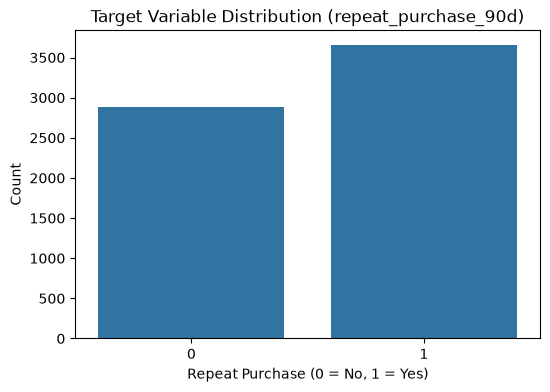

In [69]:
# Ploting the target variable distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=train_df, x='repeat_purchase_90d')
plt.title('Target Variable Distribution (repeat_purchase_90d)')
plt.xlabel('Repeat Purchase (0 = No, 1 = Yes)')
plt.ylabel('Count')
plt.show()

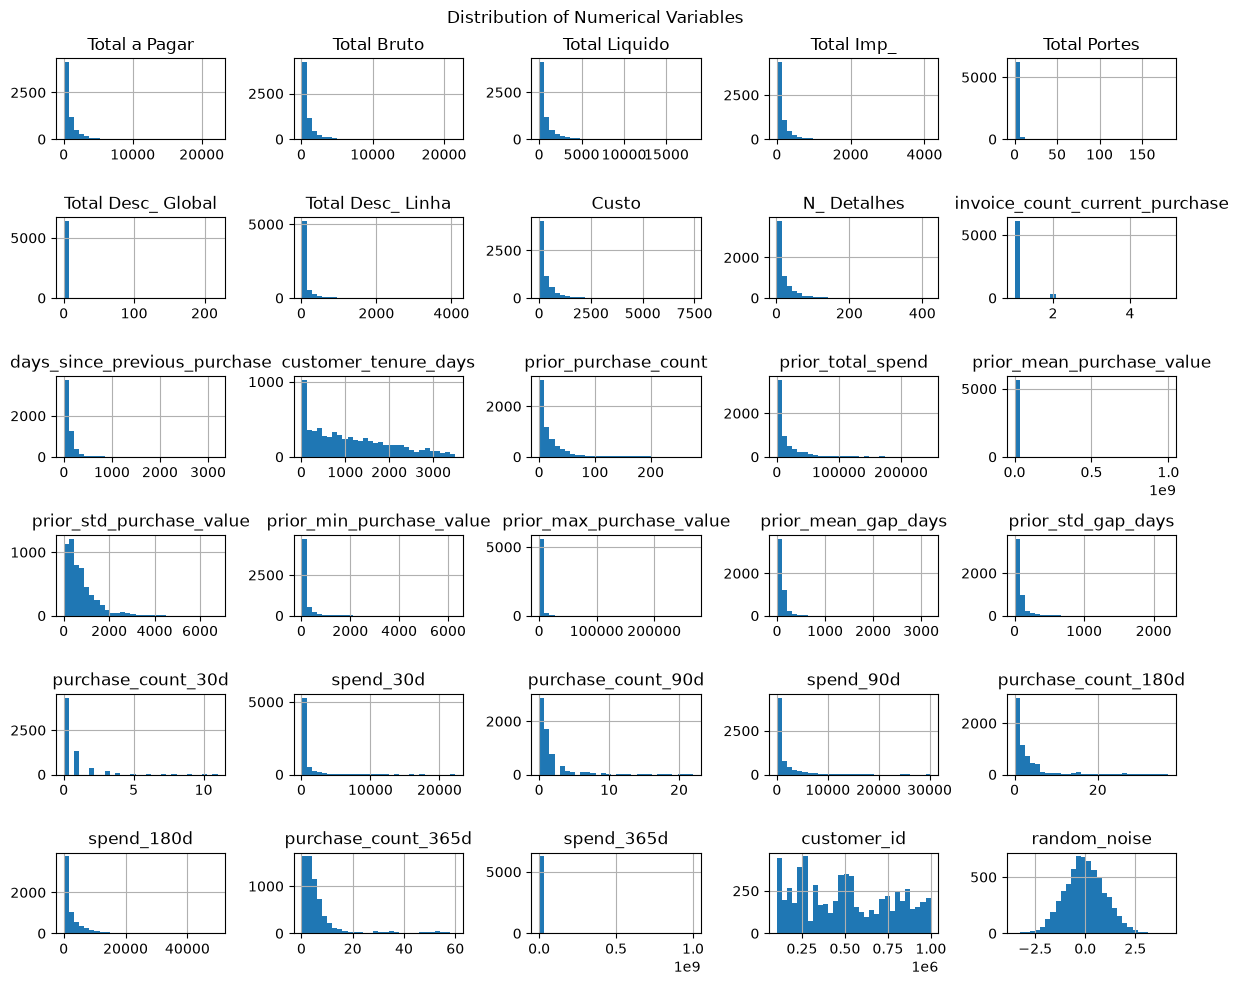

In [70]:
# Ploting the distributions of the numerical features
# we want to explore the skewness of each variable
# and to understand if there are negative values where only positive numbers make sense, or extreme values far from the mean
# we also want to see if the scale of some variables is different from others to see if we will need to do scaling

num_cols = train_df.select_dtypes(include=[np.number]).columns
num_cols = [c for c in num_cols if c not in ['ID', 'repeat_purchase_90d']]

train_df[num_cols].hist(figsize=(12, 10), bins=30)
plt.suptitle("Distribution of Numerical Variables")
plt.tight_layout()
plt.show()

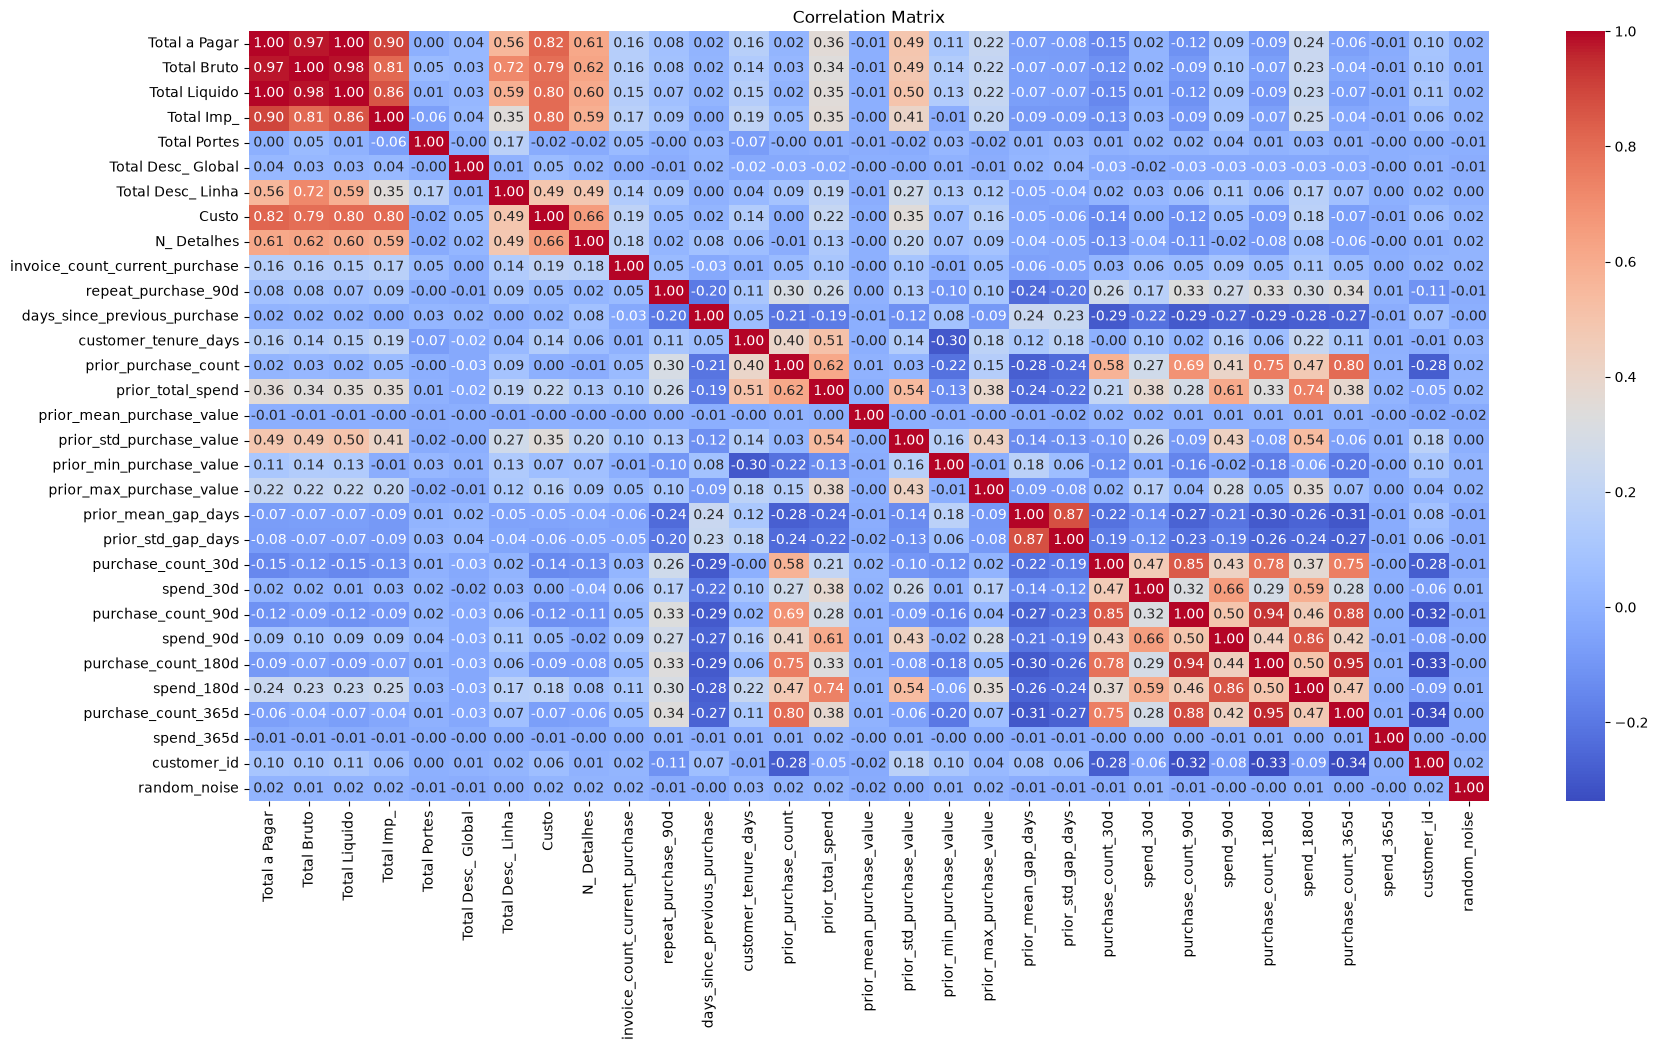

In [71]:
# multivariate relationships (Calculating Pearson's correlation coefficient between each feature)
plt.figure(figsize=(20, 10))
sns.heatmap(train_df.corr(numeric_only=True), fmt=".2f",  annot=True, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

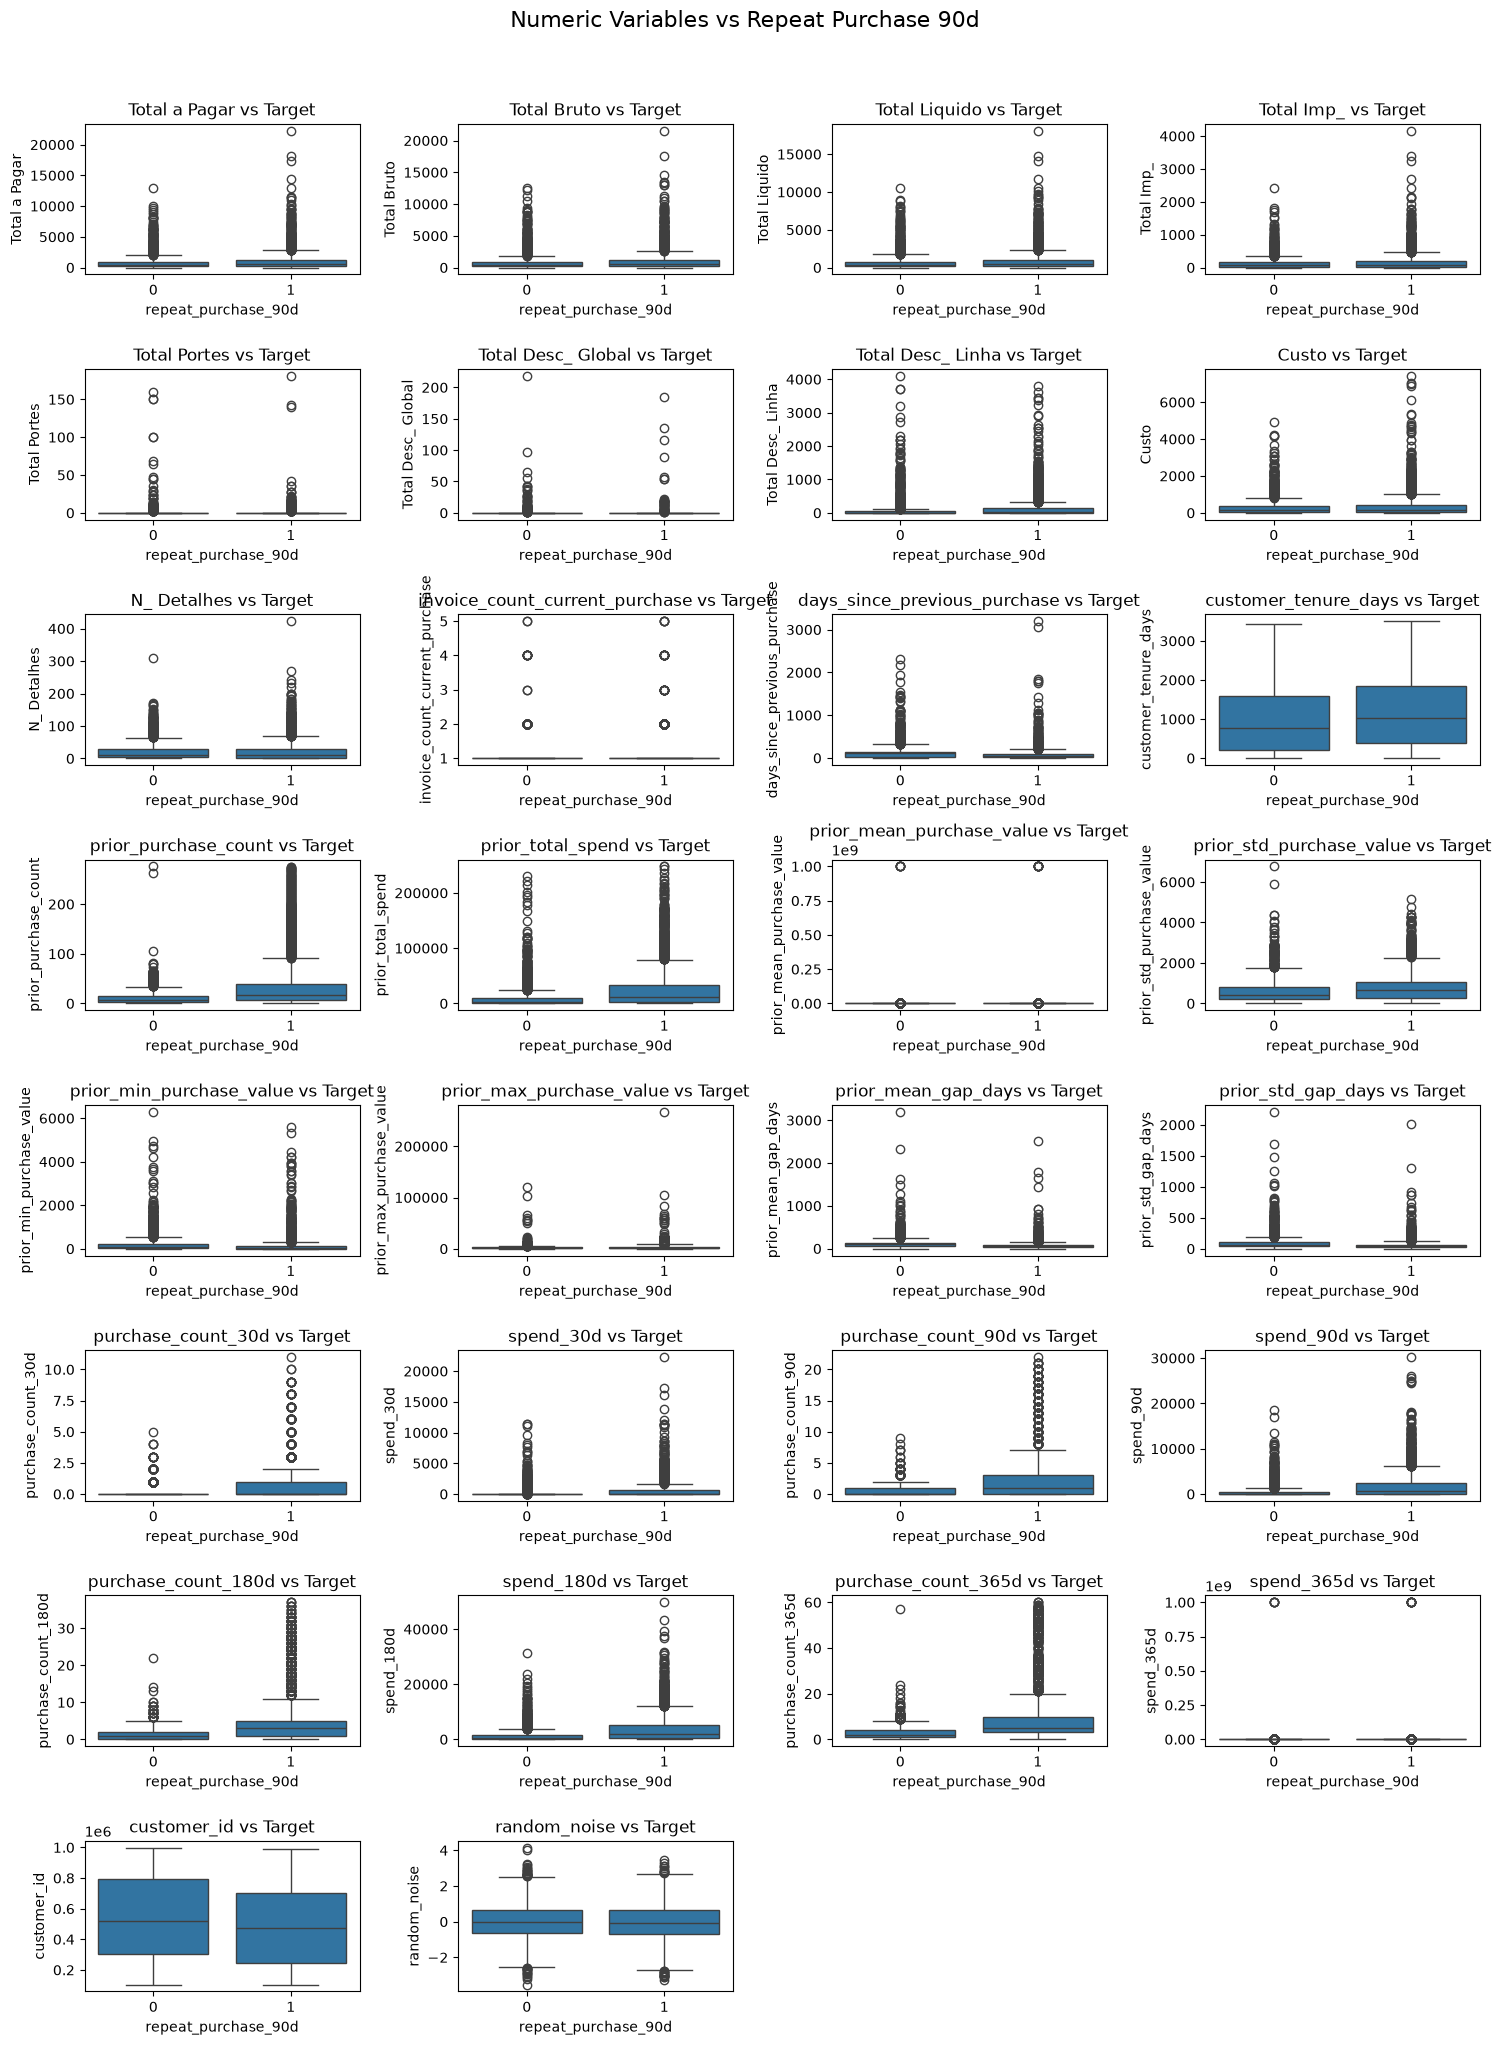

In [85]:
# Examining numerical features in relation to the target using Boxplots (checking which features are good predictors of the target)
fig, axes = plt.subplots(ceil(len(num_cols) / 4), 4, figsize=(15, 20))

# Iterarating each box plot and adding x='repeat_purchase_90d'
for ax, feat in zip(axes.flatten(), num_cols): 
    sns.boxplot(data=train_df, x='repeat_purchase_90d', y=feat, ax=ax)
    ax.set_title(f'{feat} vs Target')

# hidding the empty graphs that would appear at the end
for ax in axes.flatten()[len(num_cols):]:
    fig.delaxes(ax)

# Layout and title
plt.suptitle("Numeric Variables vs Repeat Purchase 90d", y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

# <font color='#E8800A'>4 · Modifying the data</font> <a class="anchor" id="modify"></a>

After exploring, we would normally fix problems (missing values,
outliers) and engineer better features

- Clean the data
- Create X (features) and y (target)
- Split into training and validation data
- Feature engineering

In [74]:
#Drop rows with all missing values (except customer_id and repeat_purchase_90d)
train_df = train_df[~all_missing]

In [75]:
rows_with_null = train_df.isna().any(axis=1)
per_column = train_df.isna().sum()

pd.Series({
    "rows with a null": f"{rows_with_null.sum():,} of {len(train_df):,}"
                        f" ({100 * rows_with_null.mean():.2f}%)",
    "columns with a null": f"{(per_column > 0).sum()} of {train_df.shape[1]}",
    "null cells": f"{train_df.isna().sum().sum():,}",
    "worst column": f"{per_column.idxmax()} ({per_column.max()} nulls)",
}).to_frame("missing values as the file arrives")

,missing values as the file arrives
rows with a null,"2,540 of 6,469 (39.26%)"
columns with a null,12 of 38
null cells,"7,478"
worst column,prior_std_gap_days (1413 nulls)


In [76]:
print(train_df.isnull().sum()[train_df.isnull().sum() > 0])

days_since_previous_purchase     796
prior_mean_purchase_value        797
prior_std_purchase_value        1048
prior_min_purchase_value         603
prior_max_purchase_value         603
prior_mean_gap_days             1243
prior_std_gap_days              1413
spend_365d                       195
payment_type                     195
salesperson                      194
transport_method                 196
warehouse                        195
dtype: int64


In [77]:
#Negative values